[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch14-concepts_workbook.ipynb)

# Which passage answers what did the cat sit on?

Six one-line passages each have a vector of four numbers, and so does the
question. The passages with the highest cosine go into the prompt ahead of
the question. Which passages reach the prompt? The lecture's numbers answer
it, together with the chance of an error over many agent steps, the
temperature of a contrastive loss and the memory a model's weights take.

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# The lecture's stylised values: six passages as vectors of four numbers, the bytes of a weight at 16, 8 and 4 bits,
# and three model sizes in billions of parameters.
PASSAGES = {"the cat sat on the mat": (2, 0, 2, 1), "the cat chased the mouse": (2, 0, 0, 0),
            "the dog sat on the log": (1, 2, 2, 0), "stocks fell on Monday": (0, 0, 1, 0),
            "the mat was red": (0, 0, 0, 2), "the dog ate the bone": (0, 2, 0, 0)}
BYTES = {"16 bits": 2, "8 bits": 1, "4 bits": 0.5}
MODELS = (7, 13, 70)
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def number(name, x, lo, hi):  # a number typed in a cell
    if type(x) not in (int, float) or not lo <= x <= hi:
        show = lambda v: f"{v:,}" if v == int(v) else f"{v:g}"  # noqa: E731
        raise Refused(f"{name} is {x!r}: {name} takes a number from {show(lo)} to {show(hi)}.")
    return x


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


# Step 1: the cosine divides the dot product by the two lengths; a passage sharing no number with the query scores 0.
def cosine(u, v):
    dot = sum(a * b for a, b in zip(u, v))
    return dot / math.sqrt(sum(a * a for a in u) * sum(b * b for b in v)) if dot else 0.0


def cosines(q):
    if type(q) is not tuple or len(q) != 4 or any(type(x) not in (int, float) or abs(x) > 1000 for x in q) or not any(q):
        raise Refused(f"QUERY is {q!r}: QUERY takes four numbers from -1,000 to 1,000, not all 0, as in (3, 0, 2, 0).")
    return {p: cosine(q, v) for p, v in PASSAGES.items()}


def show_retrieval(q, k):
    cos = cosines(q)
    top = sorted(cos, key=lambda p: -cos[p])[:whole("K", k, 1, 6)]
    print("; ".join(f"{p} {c:.2f}" for p, c in cos.items()) + "\ninto the prompt: " + ", ".join(top))
    fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
    b = ax.barh(list(cos), list(cos.values()), color=["C3" if p in top else "0.6" for p in cos])
    ax.bar_label(b, fmt="%.2f", padding=2, fontsize=8)
    ax.set(title=f"cosine of each passage with the query {q}; the top {k} in red", xlim=(min(0, *cos.values()) - 0.05, 1.2),
           ylim=(5.6, -0.6))
    plt.show()


# Step 2: an error in any of n independent steps at error rate p leaves the task unsolved.
def chance(per_cent, n):
    return 1 - (1 - number("ERROR", per_cent, 0, 100) / 100) ** whole("STEPS", n, 1, 1000)


def crossing(per_cent):  # the first number of steps at which an error is more likely than not
    return next((n for n in range(1, 1001) if chance(per_cent, n) > 0.5), None)


def show_errors(per_cent, n):
    c = crossing(per_cent)
    print(f"{per_cent:g} per cent a step, {n} steps: at least one error {chance(per_cent, n):.3f}; more likely than not "
          + (f"from step {c}" if c else "at no step up to 1,000"))
    fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
    for p, colour in ((1, "0.6"), (5, "C3"), (10, "0.3")):
        ax.plot(range(1, 40 + 1), [100 * chance(p, m) for m in range(1, 40 + 1)], color=colour, label=f"{p} per cent a step")
    ax.plot([n], [100 * chance(per_cent, n)], "o", color="C0", label=f"{per_cent:g} per cent, {n} steps")
    ax.set(title="chance of at least one error over n independent steps", xlabel="steps n", ylabel="per cent", ylim=(0, 100))
    ax.legend()
    plt.show()


# Step 3: the contrastive loss of one photo is a softmax over its cosines divided by the temperature, the first
# caption its own; the loss is -ln p of the own caption, in nats.
def own(cos, tau):
    if type(cos) is not tuple or not 2 <= len(cos) <= 10 or any(type(c) not in (int, float) or abs(c) > 1 for c in cos):
        raise Refused(f"COSINES is {cos!r}: COSINES takes two to ten cosines from -1 to 1, the own caption first.")
    e = [math.exp(c / number("TAU", tau, 0.01, 10)) for c in cos]
    return e[0] / sum(e)


def show_softmax(cos, tau):
    p = own(cos, tau)
    print(f"tau {tau:g}: own caption {p:.3f}, loss {-math.log(p):.3f} nats")
    taus = [1 / 1.15 ** k for k in range(22)]
    fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
    ax.semilogx(taus, [own(cos, t) for t in taus], color="C0")
    ax.plot([tau], [p], "o", color="C3", label=f"tau {tau:g}")
    ax.set(title=f"probability of the own caption, cosines {cos}", xlabel="temperature tau, log scale", ylabel="p",
           ylim=(0, 1.05))
    ax.invert_xaxis()
    ax.legend()
    plt.show()

## 1. The top passages by cosine

The query what did the cat sit on is the vector (3, 0, 2, 0). The cell
computes its cosine with each of the six passages and sends the top `K` into
the prompt. Run it. Then set `QUERY` to (0, 2, 0, 0), what did the dog eat:
which two passages reach the prompt?

the cat sat on the mat 0.92; the cat chased the mouse 0.83; the dog sat on the log 0.65; stocks fell on Monday 0.55; the mat was red 0.00; the dog ate the bone 0.00
into the prompt: the cat sat on the mat, the cat chased the mouse


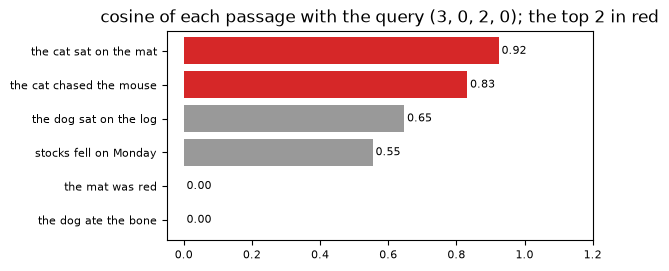

In [2]:
QUERY = (3, 0, 2, 0)
K = 2
show_retrieval(QUERY, K)

### Solution

In [3]:
cat, dog = cosines((3, 0, 2, 0)), cosines((0, 2, 0, 0))
display(Markdown(f"The cat-and-mat passage scores {cat['the cat sat on the mat']:.2f} and the cat-and-mouse passage "
                 f"{cat['the cat chased the mouse']:.2f}, so both reach the prompt; the mat was red and the dog ate the bone "
                 f"share no number with the query and score 0. For the dog query the dog ate the bone scores "
                 f"{dog['the dog ate the bone']:.2f} and the dog sat on the log {dog['the dog sat on the log']:.2f}."))

The cat-and-mat passage scores 0.92 and the cat-and-mouse passage 0.83, so both reach the prompt; the mat was red and the dog ate the bone share no number with the query and score 0. For the dog query the dog ate the bone scores 1.00 and the dog sat on the log 0.67.

## 2. Errors over many steps

An agent fails its task when any step fails. At 5 per cent a step the
chance of at least one error over 10 steps is one minus 0.95 to the power
10. The cell draws that chance for 1, 5 and 10 per cent a step over 40
steps. Run it. Then set `ERROR` to 2: from which step is an error more
likely than not?

5 per cent a step, 10 steps: at least one error 0.401; more likely than not from step 14


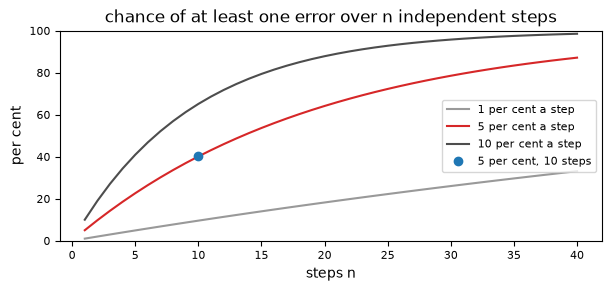

In [4]:
ERROR = 5
STEPS = 10
show_errors(ERROR, STEPS)

### Solution

In [5]:
display(Markdown(f"At 5 per cent a step, 10 steps hold at least one error with chance {chance(5, 10):.3f}, since "
                 f"0.95 to the power 10 is {0.95 ** 10:.3f}. At 2 per cent an error becomes more likely than not from step "
                 f"{crossing(2)}, where the chance is {chance(2, crossing(2)):.3f}, against {chance(2, crossing(2) - 1):.3f} "
                 f"one step earlier."))

At 5 per cent a step, 10 steps hold at least one error with chance 0.401, since 0.95 to the power 10 is 0.599. At 2 per cent an error becomes more likely than not from step 35, where the chance is 0.507, against 0.497 one step earlier.

## 3. The temperature of a contrastive loss

A cat photo has cosines 0.9, 0.5, 0.3 and 0.1 with four captions, its own
first. Divided by the temperature and put through a softmax, they give the
probability of the own caption. Run the cell at a temperature of 1. Then
set `TAU` to 0.1: what are the probability and the loss?

tau 1: own caption 0.375, loss 0.982 nats


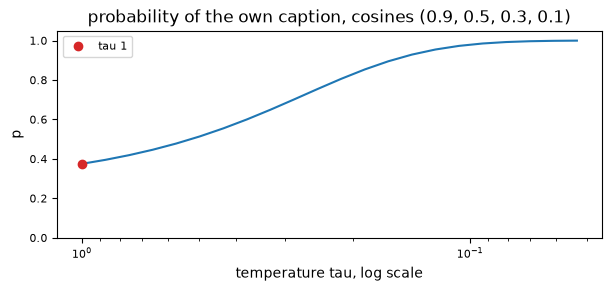

In [6]:
COSINES = (0.9, 0.5, 0.3, 0.1)
TAU = 1
show_softmax(COSINES, TAU)

### Solution

In [7]:
hot, cold = own((0.9, 0.5, 0.3, 0.1), 1), own((0.9, 0.5, 0.3, 0.1), 0.1)
display(Markdown(f"At a temperature of 1 the own caption takes {hot:.2f} and the loss is {-math.log(hot):.2f} nats. At 0.1 "
                 f"it takes {cold:.2f} and the loss falls to {-math.log(cold):.3f} nats: dividing by a small temperature "
                 f"stretches the gaps between the cosines before the softmax."))

At a temperature of 1 the own caption takes 0.37 and the loss is 0.98 nats. At 0.1 it takes 0.98 and the loss falls to 0.021 nats: dividing by a small temperature stretches the gaps between the cosines before the softmax.

## Appendix. Weights at 16, 8 and 4 bits

Weight memory is parameters times bytes per parameter: 2 bytes at 16 bits,
1 at 8 and half a byte at 4. The cell draws the weights of models of 7, 13
and 70 billion parameters against a card of 48 GB and one of 80 GB.

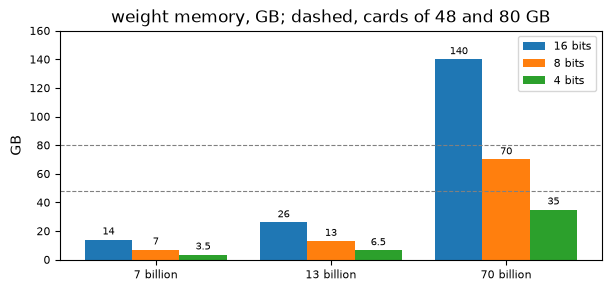

In [8]:
fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
for k, (width, b) in enumerate(BYTES.items()):
    bars = ax.bar([m + 0.27 * (k - 1) for m in range(3)], [n * b for n in MODELS], 0.27, label=width)
    ax.bar_label(bars, fmt="%g", padding=2, fontsize=7)
for gb in (48, 80):
    ax.axhline(gb, color="0.5", ls="--", lw=0.8)
ax.set_xticks(range(3), [f"{n} billion" for n in MODELS])
ax.set(title="weight memory, GB; dashed, cards of 48 and 80 GB", ylabel="GB", ylim=(0, 160))
ax.legend()
plt.show()

**Exercise.** A rank-r update of a d by k matrix trains r times (d plus k)
numbers. Set `RANK` to 8 for a matrix of 4,096 by 4,096: how many numbers
does it train, and what factor fewer than the matrix holds?

In [9]:
RANK = 16
ROWS, COLS = 4_096, 4_096
whole("RANK", RANK, 1, min(whole("ROWS", ROWS, 1, 100_000), whole("COLS", COLS, 1, 100_000)))
print(f"rank {RANK}: {RANK * (ROWS + COLS):,} trained numbers against {ROWS * COLS:,}, "
      f"a factor of {ROWS * COLS / (RANK * (ROWS + COLS)):g}")

rank 16: 131,072 trained numbers against 16,777,216, a factor of 128


### Solution

In [10]:
display(Markdown(f"Rank 8 trains {8 * (4_096 + 4_096):,} numbers for a matrix of {4_096 * 4_096:,}, a factor of "
                 f"{4_096 * 4_096 // (8 * 8_192)}, which is 4,096 over twice the rank. At rank 16 the factor is "
                 f"{4_096 * 4_096 // (16 * 8_192)}."))

Rank 8 trains 65,536 numbers for a matrix of 16,777,216, a factor of 256, which is 4,096 over twice the rank. At rank 16 the factor is 128.